# NumCompute-Stream demo: learning from a data stream

This notebook trains a decision tree on data that arrives in **chunks**, using only the
`numcompute_stream` package (NumPy + matplotlib).

**Dataset:** Electricity (elec2), 45,312 half-hourly records from the NSW electricity market.
The label is whether the price went UP (1) or DOWN (0). The rows are in time order and the
market changes over time (concept drift), so it is a good test for streaming.
2% of the feature values were removed at random (see `data/prepare_electricity.py`) so the
imputer has something to do.

**Steps:** load the CSV → split into chunks → pipeline `[SimpleImputer, StandardScaler, DecisionTreeClassifier]`
→ `StreamTrainer` (test-then-train) → logs and plots.

In [1]:
import sys
sys.path.insert(0, "..")  # so the notebook works from a fresh clone without installing

import numpy as np
import matplotlib.pyplot as plt

from numcompute_stream.io import load_csv, iter_chunks
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.preprocessing import SimpleImputer, StandardScaler
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.metrics import F1, StreamingAUC
from numcompute_stream.stats import StreamingStats
from numcompute_stream import visualise

%matplotlib inline

## 1. Load the CSV with `io.load_csv`

The last column is the target. Empty cells become `NaN`.

In [2]:
X, y = load_csv("data/electricity.csv")

print("X shape:", X.shape, " y shape:", y.shape)
print("Missing values in X: {:.2%}".format(np.isnan(X).mean()))
print("Fraction of UP (1):  {:.3f}".format(y.mean()))

X shape: (45312, 7)  y shape: (45312,)
Missing values in X: 1.98%
Fraction of UP (1):  0.425


## 2. Split into chunks with `io.iter_chunks`

Each chunk has 250 rows, so the stream has 182 chunks (the last one is smaller).

In [3]:
CHUNK_SIZE = 250
chunks = list(iter_chunks(X, y, chunk_size=CHUNK_SIZE))
print("Number of chunks:", len(chunks))
print("First chunk:", chunks[0][0].shape, " last chunk:", chunks[-1][0].shape)

Number of chunks: 182
First chunk: (250, 7)  last chunk: (62, 7)


## 3. Build the pipeline and train on the stream

- `SimpleImputer` and `StandardScaler` update their running statistics with `partial_fit` on every chunk.
- `DecisionTreeClassifier(max_depth=5, buffer_size=500)` **buffers** the chunks and retrains a new tree
  once 500 rows have arrived (every 2 chunks here), then clears the buffer.
- `StreamTrainer` uses **test-then-train**: each chunk is first predicted with the current tree (so the
  score is on unseen data) and only then used for training. The first 2 chunks are logged as `N/A`
  because no tree exists yet.

In [4]:
def make_pipeline(buffer_size):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", StandardScaler()),
        ("tree", DecisionTreeClassifier(max_depth=5, buffer_size=buffer_size)),
    ])

pipe = make_pipeline(buffer_size=500)
trainer = StreamTrainer(
    pipe,
    metrics={"f1": F1(average="binary", pos_label=1), "auc": StreamingAUC()},
    rolling_window=10,
)

for X_chunk, y_chunk in chunks:
    trainer.step(X_chunk, y_chunk)   # predict + update metrics, then partial_fit

history = trainer.history
print("Final cumulative accuracy: {:.4f}".format(history["cumulative_accuracy"][-1]))
print("Final F1 (UP class):       {:.4f}".format(history["f1"][-1]))
print("Final AUC:                 {:.4f}".format(history["auc"][-1]))
print("Number of retrains:        ", pipe.final_estimator.n_retrains_)
print("Total retrain time:         {:.3f} s".format(sum(history["retrain_time"])))

Final cumulative accuracy: 0.7390
Final F1 (UP class):       0.6811
Final AUC:                 0.7813
Number of retrains:         90
Total retrain time:         0.612 s


## 4. Per-chunk log

`acc` is the accuracy on that chunk, `cum_acc` over all scored chunks so far, `roll_acc` over the
last 10 chunks. `time_ms` is the retrain time, `buf_KB` the memory still in the buffer after the chunk,
and `nodes` the size of the current tree. Every 5th chunk is shown.

In [5]:
print(trainer.log_table(every=5))

chunk    acc  cum_acc  roll_acc  retrain  time_ms  buf_KB  nodes
    0    N/A      N/A       N/A       no     0.00    15.6      0
    5  0.864    0.845     0.845      yes     3.55     0.0     21
   10  0.608    0.720     0.720       no     0.00    15.6     27
   15  0.820    0.771     0.742      yes     4.91     0.0     31
   20  0.816    0.769     0.812       no     0.00    15.6     39
   25  0.796    0.756     0.734      yes     6.63     0.0     41
   30  0.832    0.760     0.743       no     0.00    15.6     39
   35  0.836    0.767     0.794      yes     5.64     0.0     35
   40  0.848    0.762     0.768       no     0.00    15.6     35
   45  0.876    0.771     0.786      yes     4.52     0.0     27
   50  0.748    0.765     0.778       no     0.00    15.6     49
   55  0.812    0.770     0.763      yes     5.88     0.0     33
   60  0.796    0.768     0.785       no     0.00    15.6     37
   65  0.512    0.760     0.706      yes     6.22     0.0     35
   70  0.776    0.763    

## 5. Accuracy over time

The tree is retrained every 2 chunks (500 rows). The rolling accuracy moves up and down as the
market changes (concept drift), while the cumulative accuracy settles around 0.74.

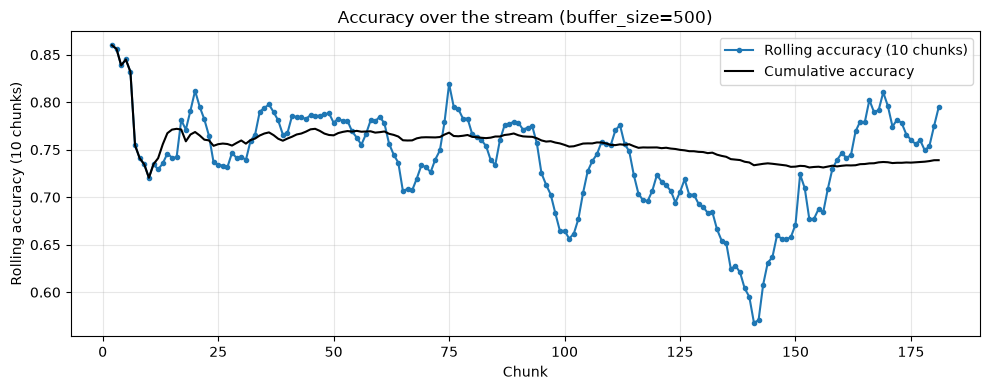

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
visualise.plot_metric_over_time(
    history["rolling_accuracy"], title="Accuracy over the stream (buffer_size=500)",
    ylabel="Rolling accuracy (10 chunks)", ax=ax, show=False,
)
ax.plot(history["cumulative_accuracy"], label="Cumulative accuracy", color="black")
ax.legend()
fig.savefig("figures/accuracy_over_time.png", dpi=150)
plt.show()

## 6. Comparing two buffer sizes

A small buffer retrains often on recent data, so it follows changes in the market quickly but costs more
retrain time. A large buffer retrains rarely and each tree is trained on more rows, but it reacts
to drift late.

buffer_size= 500: cumulative accuracy 0.7390, retrains  90, retrain time 0.622 s


buffer_size=2000: cumulative accuracy 0.7315, retrains  22, retrain time 0.315 s


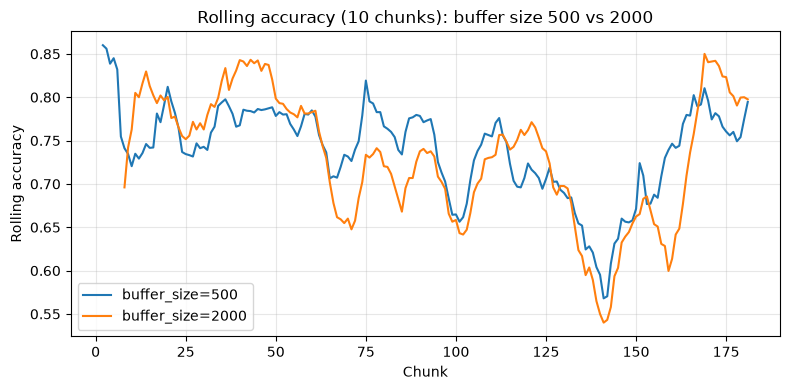

(<Figure size 800x400 with 1 Axes>,
 <Axes: title={'center': 'Rolling accuracy (10 chunks): buffer size 500 vs 2000'}, xlabel='Chunk', ylabel='Rolling accuracy'>)

In [7]:
results = {}
for buffer_size in (500, 2000):
    t = StreamTrainer(make_pipeline(buffer_size), rolling_window=10)
    t.run(iter_chunks(X, y, chunk_size=CHUNK_SIZE))
    results[buffer_size] = t.history
    print("buffer_size={:>4}: cumulative accuracy {:.4f}, retrains {:>3}, retrain time {:.3f} s".format(
        buffer_size, t.history["cumulative_accuracy"][-1], sum(t.history["retrained"]),
        sum(t.history["retrain_time"])))

visualise.compare_models(
    results[500]["rolling_accuracy"], results[2000]["rolling_accuracy"],
    labels=("buffer_size=500", "buffer_size=2000"),
    title="Rolling accuracy (10 chunks): buffer size 500 vs 2000",
    ylabel="Rolling accuracy", save_path="figures/buffer_comparison.png",
)

## 7. Predictions vs ground truth on the last chunk

The last chunk (62 rows) is predicted by the tree trained before it arrived. Wrong predictions are red.

Accuracy on the last chunk: 0.774


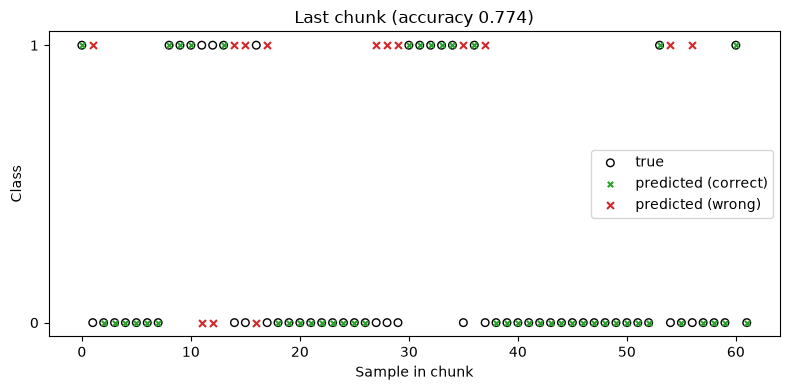

(<Figure size 800x400 with 1 Axes>,
 <Axes: title={'center': 'Last chunk (accuracy 0.774)'}, xlabel='Sample in chunk', ylabel='Class'>)

In [8]:
y_true_last, y_pred_last = trainer.last_y_true, trainer.last_y_pred
print("Accuracy on the last chunk: {:.3f}".format(np.mean(y_true_last == y_pred_last)))

visualise.plot_predictions_vs_ground_truth(
    y_true_last.astype(int), y_pred_last.astype(int),
    title="Last chunk", save_path="figures/predictions_last_chunk.png",
)

## 8. Streaming statistics

`StreamingStats.update_stats` keeps running mean/variance/min/max and a fixed-bin histogram without
storing old chunks. The quantiles are approximate (error at most one bin width, here 0.01).

Streaming mean: [4.0023e+00 5.0000e-01 5.7900e-02 4.2550e-01 3.5000e-03 4.2300e-01
 5.0050e-01]
np.nanmean:     [4.0023e+00 5.0000e-01 5.7900e-02 4.2550e-01 3.5000e-03 4.2300e-01
 5.0050e-01]
Streaming std:  [1.9986 0.2948 0.0401 0.1633 0.0103 0.1209 0.1533]
np.nanstd:      [1.9986 0.2948 0.0401 0.1633 0.0103 0.1209 0.1533]

nswprice median: approx 0.0492, exact 0.0486


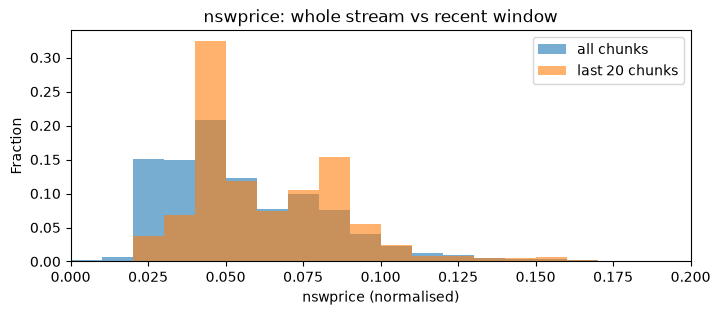

In [9]:
stats = StreamingStats(bin_edges=np.linspace(0, 1, 101), window=20)
for X_chunk, _ in chunks:
    stats.update_stats(X_chunk)

names = ["day", "period", "nswprice", "nswdemand", "vicprice", "vicdemand", "transfer"]
print("Streaming mean:", np.round(stats.mean_, 4))
print("np.nanmean:    ", np.round(np.nanmean(X, axis=0), 4))
print("Streaming std: ", np.round(stats.std_, 4))
print("np.nanstd:     ", np.round(np.nanstd(X, axis=0), 4))

j = names.index("nswprice")
print("\nnswprice median: approx {:.4f}, exact {:.4f}".format(
    stats.quantile(0.5)[j], np.nanquantile(X[:, j], 0.5)))

fig, ax = plt.subplots(figsize=(8, 3))
centres = (stats.bin_edges[:-1] + stats.bin_edges[1:]) / 2
ax.bar(centres, stats.histogram()[j] / stats.histogram()[j].sum(), width=0.01, alpha=0.6, label="all chunks")
ax.bar(centres, stats.histogram(recent=True)[j] / stats.histogram(recent=True)[j].sum(), width=0.01, alpha=0.6, label="last 20 chunks")
ax.set_xlim(0, 0.2)
ax.set_xlabel("nswprice (normalised)")
ax.set_ylabel("Fraction")
ax.set_title("nswprice: whole stream vs recent window")
ax.legend()
plt.show()

## 9. End of the stream

Rows left in the buffer are not used until `flush()` is called. The spec only retrains when the
buffer is full, so `flush()` is an extra step for the end of a stream.

In [10]:
tree = pipe.final_estimator
print("Rows waiting in the buffer:", tree.n_buffered_)
tree.flush()
print("After flush: buffer", tree.n_buffered_, "rows, retrains", tree.n_retrains_)

Rows waiting in the buffer: 312
After flush: buffer 0 rows, retrains 91


## Summary

- The tree learns from the stream chunk by chunk with buffered `partial_fit`.
- Test-then-train cumulative accuracy is about 0.74 with `buffer_size=500`.
- Smaller buffers follow concept drift better; larger buffers retrain less often (see `benchmark/bench_buffer_size.py`).